# Setup

This notebook reads Sentinel-1 radar images with Python. It works the two experiments of the guide
[Reading radar images](https://ahmadammar.github.io/teaching/sar/) step by step: the basics over London, then mapping
the 2022 flood in Sindh. The images were exported from Google Earth Engine by the scripts of that guide; here they are
small GeoTIFF files, downloaded by the first cell, so no Earth Engine account is needed.

Libraries: **rasterio** reads and writes georeferenced rasters (GeoTIFF); **numpy** does arithmetic on whole images;
**matplotlib** draws them. Google Colab does not include rasterio, so the first cell installs it when missing.

In [1]:
import importlib.util, json, subprocess, sys, urllib.request
from pathlib import Path
if importlib.util.find_spec("rasterio") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rasterio"], check=True)
import numpy as np
import rasterio
from rasterio.warp import transform as reproject_points
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110})
BASE = "https://raw.githubusercontent.com/AhmadAmmar/AhmadAmmar.github.io/main/guides/radar-python/notebooks/data_local/"
FILES = ["london_mean_vv_10m.tif", "london_single_vv_10m.tif", "london_2024_mean_80m.tif", "sindh_flood_200m.tif", "london_stats.json", "sindh_stats.json"]
DATA, LOCAL = Path("data"), Path("data_local")
DATA.mkdir(exist_ok=True)
for f in FILES:
    if not (DATA / f).exists():
        (DATA / f).write_bytes((LOCAL / f).read_bytes() if (LOCAL / f).exists() else urllib.request.urlopen(BASE + f, timeout=120).read())
    print(f"{f:28s} {(DATA / f).stat().st_size / 1e6:5.2f} MB")

london_mean_vv_10m.tif        2.85 MB
london_single_vv_10m.tif      2.90 MB
london_2024_mean_80m.tif      4.13 MB
sindh_flood_200m.tif          3.91 MB
london_stats.json             0.00 MB
sindh_stats.json              0.00 MB


# What a radar image measures

Sentinel-1 is a radar satellite. It sends pulses of microwaves (wavelength about 5.5 cm) sideways and down at the
ground and measures how much energy comes back. Because it brings its own illumination, it sees through cloud and at
night: that is why it is used for floods, which come with cloud.

What comes back depends on the surface. A **smooth** surface, such as calm water or a runway, acts like a mirror and
sends the pulse away from the satellite: it looks **dark**. A **rough** surface, such as a field, scatters energy in
all directions, some of it back: medium. **Buildings** form corners with the ground that send energy straight back:
**bright**. The quantity measured is the **backscatter coefficient**, σ⁰ (sigma-nought), the share of energy returned
per unit area. It spans a huge range, from about 0.001 for calm water to above 10 for a building corner, so it is
given in **decibels (dB)**:

$$ \sigma^0_{\text{dB}} = 10 \log_{10}(\sigma^0_{\text{linear}}), \qquad \sigma^0_{\text{linear}} = 10^{\sigma^0_{\text{dB}}/10} $$

Every 10 dB is a factor of ten, every 3 dB roughly a factor of two. Negative dB values are normal: they mean less
than the reference, not negative energy.

In [2]:
for lin in [0.001, 0.01, 0.1, 0.5, 1, 2, 10]:
    print(f"linear {lin:7.3f}  ->  {10 * np.log10(lin):+6.1f} dB")

linear   0.001  ->   -30.0 dB
linear   0.010  ->   -20.0 dB
linear   0.100  ->   -10.0 dB
linear   0.500  ->    -3.0 dB
linear   1.000  ->    +0.0 dB
linear   2.000  ->    +3.0 dB
linear  10.000  ->   +10.0 dB


# Open a radar image

A GeoTIFF holds a grid of numbers (one or more **bands**) and the information that places it on the Earth: the
coordinate reference system (CRS) and the **transform**, which gives the coordinates of the top-left corner and the
size of a pixel. Here: the mean VV backscatter (in dB) of all Sentinel-1 scenes of 2024 over central London, at 10 m.

bands: 1 | rows x columns: (806, 1062) | CRS: EPSG:27700 | pixel size: (10.0, 10.0) m
left, bottom, right, top: [524950, 174980, 535570, 183040]
values (dB): min -19.3, 2nd percentile -13.3, median -4.4, 98th percentile 9.8, max 37.2


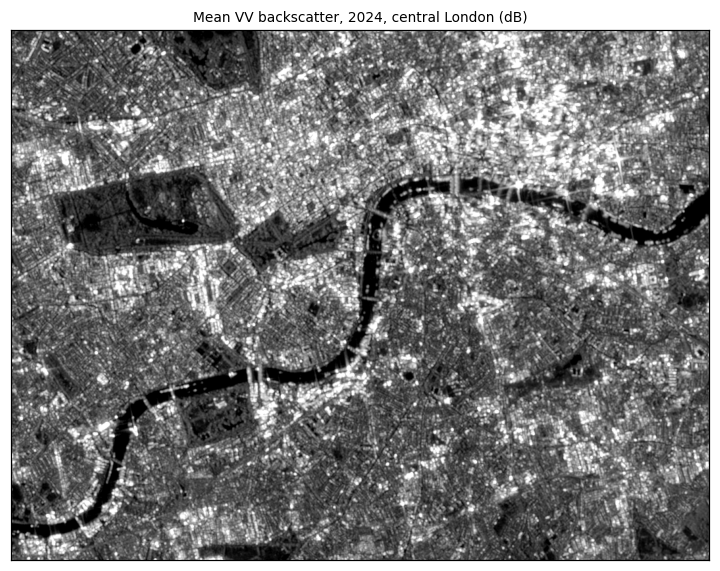

In [3]:
with rasterio.open(DATA / "london_mean_vv_10m.tif") as src:
    vv = src.read(1)
    print("bands:", src.count, "| rows x columns:", src.shape, "| CRS:", src.crs, "| pixel size:", src.res, "m")
    print("left, bottom, right, top:", [round(v) for v in src.bounds])
    london_transform, london_crs = src.transform, src.crs
print(f"values (dB): min {np.nanmin(vv):.1f}, 2nd percentile {np.nanpercentile(vv, 2):.1f}, median {np.nanmedian(vv):.1f}, "
      f"98th percentile {np.nanpercentile(vv, 98):.1f}, max {np.nanmax(vv):.1f}")

def show(img, ax, title, lo=2, hi=98, cmap="gray"):
    """Display with a percentile stretch: the darkest 2% black, the brightest 2% white, the rest in between."""
    a, b = np.nanpercentile(img, [lo, hi])
    ax.imshow(img, cmap=cmap, vmin=a, vmax=b)
    ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])

fig, ax = plt.subplots(figsize=(7, 5.3))
show(vv, ax, "Mean VV backscatter, 2024, central London (dB)")
plt.tight_layout(); plt.show()

**How to read the image.** Each pixel is 10 m × 10 m. Grey level is backscatter: dark is low (smooth surfaces), light
is high. The values were stretched so the darkest 2% are black and the brightest 2% white; without the stretch a few
very bright corners would make the rest look uniformly dark. You can now read London as radar sees it: the **Thames**
is a dark band winding across the middle (smooth water); **parks** such as Hyde Park are mid-grey (grass and trees);
the **City** and **Canary Wharf** are the brightest areas (building corners); reservoirs in the west are dark patches.

# Averaging: always in linear units

Because dB is a logarithm, the average of dB values is not the dB of the average. Two pixels at −30 dB (water) and
0 dB (a bright roof): their mean in dB is −15 dB. In linear units they are 0.001 and 1, whose mean is 0.5005, or −3 dB.
The dB mean is too dark by 12 dB, a factor of about 16. Every average (over time, over an area, when making pixels
bigger) must be taken in linear units and converted back.

In [4]:
pair = np.array([-30.0, 0.0])
print(f"mean of dB values: {pair.mean():.1f} dB;  mean in linear units: {10 * np.log10(np.mean(10 ** (pair / 10))):.1f} dB")
whole_db = np.nanmean(vv)
whole_lin = 10 * np.log10(np.nanmean(10 ** (vv / 10)))
print(f"whole London image: mean of dB values {whole_db:.2f} dB, mean in linear units {whole_lin:.2f} dB, "
      f"difference {whole_lin - whole_db:.2f} dB")

mean of dB values: -15.0 dB;  mean in linear units: -3.0 dB
whole London image: mean of dB values -3.53 dB, mean in linear units 1.72 dB, difference 5.25 dB


Over the whole image the difference is a few dB: the dB mean is biased low because it gives too little weight to the
bright pixels. That is large compared with the differences we want to detect, such as a field turning to floodwater.

# Speckle: why one image is noisy

Each radar pixel adds up echoes from many small scatterers within it. They interfere, sometimes adding and sometimes
cancelling, so even a uniform field shows a grainy pattern called **speckle**. It is not noise in the instrument; it is
part of how coherent radar works. Averaging many images (or many neighbouring pixels) reduces it. The **equivalent
number of looks (ENL)** measures how smooth a uniform area is: ENL = mean² / variance of the linear values. One raw
Sentinel-1 image has an ENL of about 4–5; averaging n independent images multiplies it by about n.

ENL in the most uniform 80 m blocks: one scene 4.5, mean of 149 scenes 8.8 (1.9 times smoother)
(the manual, over a uniform area: ENL 4.4 for one scene, 20.9 for the mean)


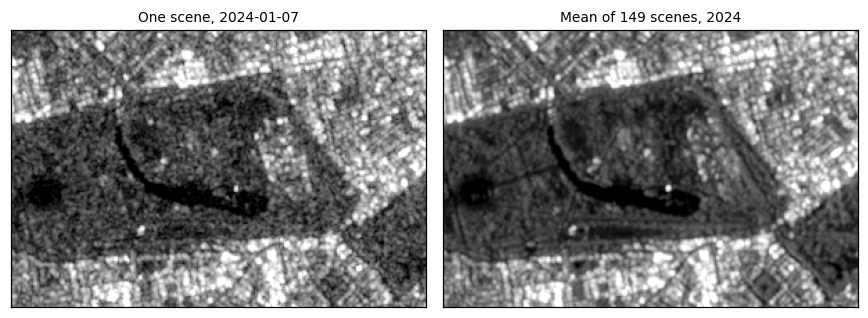

In [5]:
with rasterio.open(DATA / "london_single_vv_10m.tif") as src:
    one = src.read(1)
stats_l = json.loads((DATA / "london_stats.json").read_text())
def block_enl(img_db, k=8):
    """ENL = mean² / variance of linear values, in every k x k block of pixels."""
    lin = 10 ** (img_db / 10)
    h, w = lin.shape[0] // k * k, lin.shape[1] // k * k
    b = lin[:h, :w].reshape(h // k, k, w // k, k).transpose(0, 2, 1, 3).reshape(-1, k * k)
    b = b[np.isfinite(b).all(axis=1)]
    return b.mean(axis=1) ** 2 / b.var(axis=1)

# ENL only means something in uniform areas, so use the most uniform blocks: the top 10% of block ENL values
e_one, e_mean = np.percentile(block_enl(one), 90), np.percentile(block_enl(vv), 90)
print(f"ENL in the most uniform 80 m blocks: one scene {e_one:.1f}, mean of {stats_l['nScenesLondon']} scenes {e_mean:.1f} "
      f"({e_mean / e_one:.1f} times smoother)")
print(f"(the manual, over a uniform area: ENL {stats_l['enlOne']} for one scene, {stats_l['enlMany']} for the mean)")
lon, lat = -0.165, 51.507                                   # Hyde Park, for the zoom below
x, y = reproject_points("EPSG:4326", london_crs, [lon], [lat])
row, col = rasterio.transform.rowcol(london_transform, x[0], y[0])

fig, axes = plt.subplots(1, 2, figsize=(8, 3.6))
zoom = (slice(row - 100, row + 100), slice(col - 150, col + 150))
show(one[zoom], axes[0], f"One scene, {stats_l['sceneDate']}")
show(vv[zoom], axes[1], f"Mean of {stats_l['nScenesLondon']} scenes, 2024")
plt.tight_layout(); plt.show()

**How to read the figure.** Both panels show the same 2 km × 3 km around Hyde Park with the same stretch. On the left,
one image: grainy, so single pixels cannot be trusted. On the right, the mean of a year: the speckle has averaged out
and paths, the lake and building edges are clear. The printed ENL says the same in numbers: in the most uniform
blocks, the year's mean is about twice as smooth as one scene. That is far less than 149 scenes might suggest, for two
reasons: central London has few truly uniform areas, so even the "most uniform" blocks contain real variation; and
scenes taken from the same orbit are not independent views. Over a uniform field the manual measured a much larger
gain. **What it means in practice:** compare averages of several images, or average neighbouring pixels, before
drawing conclusions from single pixels; that costs time resolution or spatial detail.

# Polarisation: VV, VH and their difference

Sentinel-1 sends vertically polarised pulses and records two returns. **VV** (vertical in, vertical out) is strong
from surfaces and corners. **VH** (vertical in, horizontal out) needs the wave's polarisation to be twisted, which
happens mostly through repeated scattering inside volumes such as tree canopies and crops. So VV − VH (in dB) is
**small for vegetation** (a lot of twisted return) and **large for smooth surfaces and buildings**.

place (240 m window)                 VV dB   VH dB  VV-VH
Heathrow Airport                       9.5    -1.4   10.9
River Thames, central London          -9.2   -15.8    6.6
Hyde Park                             -6.9   -14.0    7.1
Canary Wharf                          13.9     4.6    9.3
Richmond Park                        -12.1   -18.1    6.0
Reservoir south-west of Heathrow     -12.8   -22.0    9.3

brightest VV: Canary Wharf | darkest VV: Reservoir south-west of Heathrow | smallest VV-VH (most vegetation-like): Richmond Park


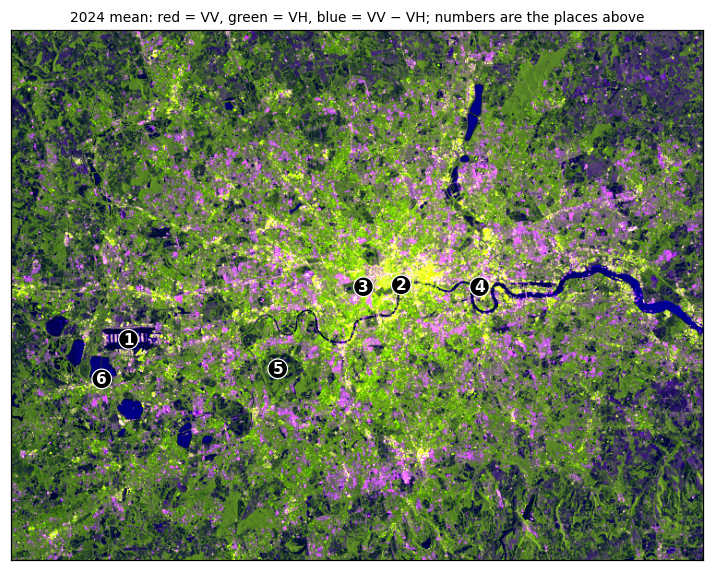

In [6]:
with rasterio.open(DATA / "london_2024_mean_80m.tif") as src:
    vv80, vh80, ratio80 = src.read()
    t80 = src.transform
places = [("Heathrow Airport", -0.46, 51.47), ("River Thames, central London", -0.118, 51.508), ("Hyde Park", -0.165, 51.507),
          ("Canary Wharf", -0.02, 51.505), ("Richmond Park", -0.275, 51.445), ("Reservoir south-west of Heathrow", -0.495, 51.44)]
xs, ys = reproject_points("EPSG:4326", london_crs, [p[1] for p in places], [p[2] for p in places])
def place_mean(img_db, r, c, k=1):
    """Mean of a (2k+1) x (2k+1) window around a pixel, in linear units, back in dB: one pixel can land on a pond or a path."""
    w = img_db[r - k:r + k + 1, c - k:c + k + 1]
    return 10 * np.log10(np.nanmean(10 ** (w / 10)))
rows_ = []
for (name, _, _), xx, yy in zip(places, xs, ys):
    r, c = rasterio.transform.rowcol(t80, xx, yy)
    v, h = place_mean(vv80, r, c), place_mean(vh80, r, c)
    rows_.append((name, v, h, v - h))
print(f"{'place (240 m window)':34s} {'VV dB':>7s} {'VH dB':>7s} {'VV-VH':>6s}")
for name, v, h, d in rows_:
    print(f"{name:34s} {v:7.1f} {h:7.1f} {d:6.1f}")
print("\nbrightest VV:", max(rows_, key=lambda r: r[1])[0], "| darkest VV:", min(rows_, key=lambda r: r[1])[0],
      "| smallest VV-VH (most vegetation-like):", min(rows_, key=lambda r: r[3])[0])

def scale(a):
    lo, hi = np.nanpercentile(a, [2, 98]); return np.clip((a - lo) / (hi - lo), 0, 1)
rgb = np.dstack([scale(vv80), scale(vh80), scale(ratio80)])
fig, ax = plt.subplots(figsize=(7, 5.3))
ax.imshow(rgb); ax.set_xticks([]); ax.set_yticks([])
for k, ((name, _, _), xx, yy) in enumerate(zip(places, xs, ys), 1):
    r, c = rasterio.transform.rowcol(t80, xx, yy)
    ax.annotate(str(k), (c, r), color="white", fontsize=10, ha="center", va="center", fontweight="bold",
                bbox=dict(boxstyle="circle,pad=0.15", fc="black", ec="white", lw=0.8))
ax.set_title("2024 mean: red = VV, green = VH, blue = VV − VH; numbers are the places above", fontsize=9)
plt.tight_layout(); plt.show()

**How to read the table.** Each row is one place; the columns are the mean VV and VH backscatter in dB and their
difference, each averaged over a 240 m window (in linear units) because a single pixel can fall on a pond or a path.
Compare rows rather than reading single numbers: the line under the table names the brightest and darkest place and
the one with the smallest VV − VH. Expect open water to be darkest, dense buildings and the airport's hard surfaces and
hangars brightest, and vegetated parks to have the smallest difference, because their canopies twist the polarisation.
Where a place does not fit (a park reading as dark as water), look at the image: its window may include a lake.

**How to read the false-colour image.** Each colour channel shows one band, stretched from its darkest 2% to its
brightest 2%: **red** is VV, **green** is VH, **blue** is VV − VH. Colours mix as on a screen, so read them by asking
which bands are high. **Dark blue** (the Thames, the reservoirs): VV and VH both very low but their difference large,
the signature of smooth water. **Green** (parks, fields, woods): relatively strong VH, the twisted return from
vegetation. **Yellow to white** (central London, Canary Wharf): VV and VH both high, from building corners and
clutter. **Purple to pink**: high VV with a large difference, typical of smooth hard surfaces and buildings facing
the satellite, such as runways and warehouses. The numbered circles are the six places in the table.

# Mapping a flood: Sindh, 2022

In August and September 2022 extreme monsoon rain flooded a third of Pakistan. Cloud hid the ground from optical
satellites for weeks; radar kept seeing. Floodwater is smooth, so it turns dark. The method: take the mean VV of the
same weeks in a normal year (2021) and in the flood year (2022), find a threshold that separates dark water from land,
and call a pixel **flooded** if it is darker than the threshold in 2022, was not in 2021, and is not normally water.

grid (781, 653), pixel 200 m = 0.04 km²; mapped area 20,400 km²


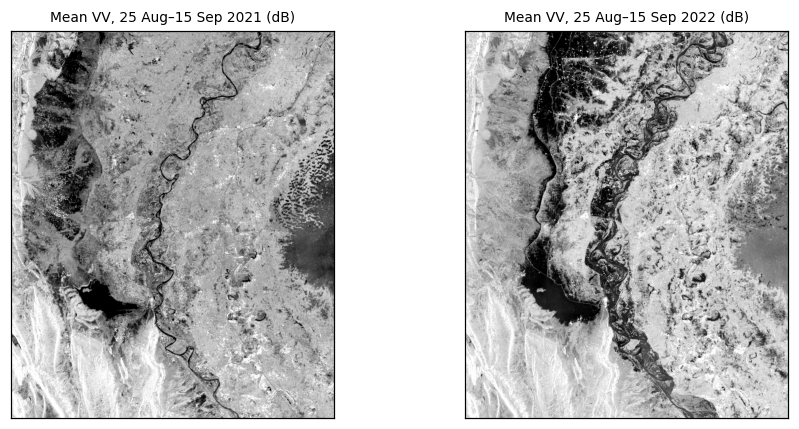

In [7]:
with rasterio.open(DATA / "sindh_flood_200m.tif") as src:
    pre, post, occurrence = src.read()
    pixel_km2 = abs(src.res[0] * src.res[1]) / 1e6
print(f"grid {pre.shape}, pixel {src.res[0]:.0f} m = {pixel_km2:.2f} km²; mapped area {np.isfinite(post).sum() * pixel_km2:,.0f} km²")

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
show(pre, axes[0], "Mean VV, 25 Aug–15 Sep 2021 (dB)")
show(post, axes[1], "Mean VV, 25 Aug–15 Sep 2022 (dB)")
plt.tight_layout(); plt.show()

**How to read the two images.** Same area, same weeks of the year, same stretch. Dark is smooth: in 2021 the dark
areas are the Indus and Manchar Lake; in 2022 large new dark areas spread across the plains west of the river. The
difference between the panels is the flood.

# Choosing the threshold from the data: Otsu's method

In the 2022 image the pixels form two groups, water (dark) and land (brighter). **Otsu's method** tries every possible
threshold t and keeps the one that makes the two groups most distinct, by maximising the between-group variance:

$$ \sigma_b^2(t) = w_0(t)\,w_1(t)\,\bigl[\mu_0(t) - \mu_1(t)\bigr]^2 $$

where w₀ and w₁ are the shares of pixels below and above t, and μ₀ and μ₁ their means.

Otsu threshold on this 200 m grid: -13.8 dB (the manual, on the 100 m grid: -14.1 dB)


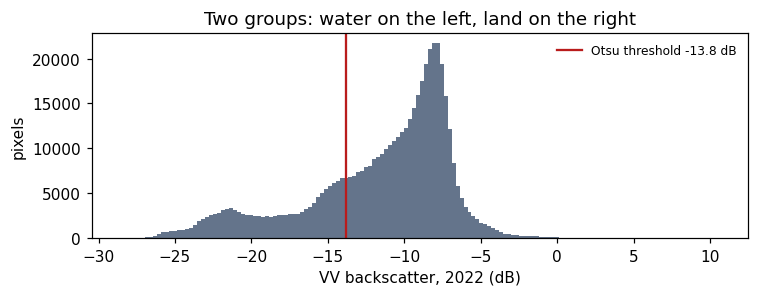

In [8]:
def otsu(values, bins=256):
    v = values[np.isfinite(values)]
    count, edges = np.histogram(v, bins=bins)
    mids = (edges[:-1] + edges[1:]) / 2
    w0 = np.cumsum(count) / count.sum()                  # share below each candidate threshold
    m0 = np.cumsum(count * mids) / count.sum()           # running sum of the means
    mean_all = m0[-1]
    between = (mean_all * w0 - m0) ** 2 / (w0 * (1 - w0) + 1e-12)
    return float(mids[np.argmax(between)])

t = otsu(post)
stats_s = json.loads((DATA / "sindh_stats.json").read_text())
print(f"Otsu threshold on this 200 m grid: {t:.1f} dB (the manual, on the 100 m grid: {stats_s['threshold']} dB)")
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(post[np.isfinite(post)], bins=150, color="#64748b")
ax.axvline(t, color="#b91c1c", lw=1.5, label=f"Otsu threshold {t:.1f} dB")
ax.set(xlabel="VV backscatter, 2022 (dB)", ylabel="pixels", title="Two groups: water on the left, land on the right")
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

**How to read the histogram.** x: backscatter in dB; y: how many pixels have that value. Two humps: a smaller one on
the left (dark, smooth: water) and a larger one on the right (land). The red line is the threshold Otsu's method
chose, in the valley between them. It differs slightly from the manual's because coarser pixels mix water and land at
the edges and shift the humps; that difference is a first hint of how uncertain the flood area is.

# From threshold to flood map and area

A pixel is **flooded** if it is below the threshold in 2022, was above it in 2021, and is water less than 50% of the time
in the JRC Global Surface Water record (so permanent rivers and lakes are excluded).

flooded: 3,283 km²  (the manual on 100 m pixels: 3,458 km²; the difference comes from the coarser pixels)
water already there in 2021: 2,102 km²; permanent water: 324 km²
threshold -14.8 dB -> 3,148 km²  (-4%)
threshold -12.8 dB -> 3,278 km²  (-0%)


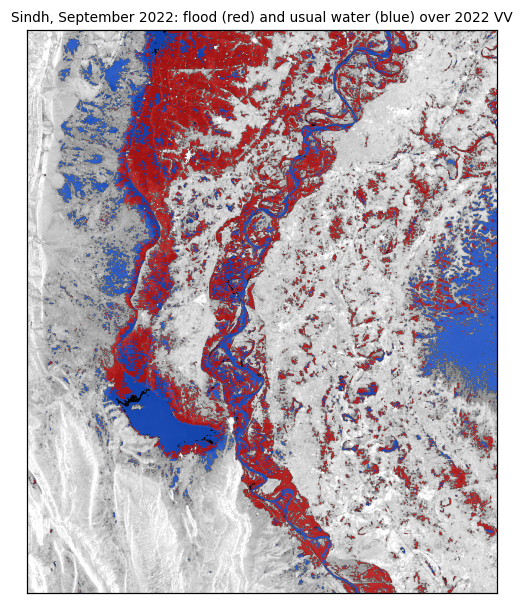

In [9]:
water22, water21 = post < t, pre < t
permanent = occurrence >= 50
flood = water22 & ~water21 & ~permanent
area = flood.sum() * pixel_km2
print(f"flooded: {area:,.0f} km²  (the manual on 100 m pixels: {stats_s['floodKm']:,} km²; the difference comes from the coarser pixels)")
print(f"water already there in 2021: {(water21 & water22).sum() * pixel_km2:,.0f} km²; permanent water: {permanent.sum() * pixel_km2:,.0f} km²")
for dt in (-1.0, +1.0):
    alt = (post < t + dt) & ~(pre < t + dt) & ~permanent
    print(f"threshold {t + dt:.1f} dB -> {alt.sum() * pixel_km2:,.0f} km²  ({100 * (alt.sum() * pixel_km2 / area - 1):+.0f}%)")

fig, ax = plt.subplots(figsize=(7, 5.6))
show(post, ax, "Sindh, September 2022: flood (red) and usual water (blue) over 2022 VV")
over = np.zeros((*post.shape, 4))
over[flood] = [0.85, 0.1, 0.1, 0.75]; over[water21 & water22] = [0.1, 0.35, 0.9, 0.75]
ax.imshow(over); plt.tight_layout(); plt.show()

**How to read the map.** The grey background is the 2022 radar image. Red pixels met all three flood rules: new water
in 2022. Blue pixels were water in both years. The red areas spread west of the Indus around Manchar Lake and across the
plains of Dadu district, which matches reported flooding there.

**What the numbers say.** The flooded area is a few thousand km², close to the manual's estimate on finer pixels.
Moving the threshold by 1 dB changes the area by only a few percent, and not symmetrically. That is because the rule
uses the same threshold for both years: raising it adds water in 2022, but also in 2021, which is then excluded, so the
two changes partly cancel. Report the area with this range; it is the honest uncertainty of a threshold method, and it
leaves out the larger errors listed next.

**What they do not say.** Radar misses water under trees and between buildings (the beam does not reach it), can
mistake smooth sand or tarmac for water, and sees only the dates it passed over. Pixels are not independent, so area
counts are not "samples" for statistical tests (see the guide
[Hypothesis testing with climate data](https://ahmadammar.github.io/teaching/hypothesis-testing/)).

# What you have learned

You opened georeferenced radar images and read their size, grid and coordinates; converted between dB and linear
units and saw why averaging must be done in linear units; measured speckle and how averaging reduces it; used two
polarisations to tell water, vegetation and buildings apart; chose a threshold from the data with Otsu's method; and
mapped a flood with an area and its uncertainty.